In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive, files
import json
import os
import io

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import zipfile
import shutil

MODEL_PATH = "/content/drive/MyDrive/tomato_mobilenetv2_5classes.keras.zip"

assert os.path.exists(MODEL_PATH), "Model file not found!"

# Keras model internally stored as ZIP
KERAS_PATH = "/content/tomato_model.keras"

shutil.copy2(MODEL_PATH, KERAS_PATH)

model = tf.keras.models.load_model(
    KERAS_PATH,
    compile=False
)

print("Model loaded successfully!")
print("Input:", model.input_shape)
print("Output:", model.output_shape)

Model loaded successfully!
Input: (None, 224, 224, 3)
Output: (None, 5)


In [4]:
CLASSES_PATH = "/content/drive/MyDrive/class_names.json"

with open(CLASSES_PATH, "r") as f:
    class_names = json.load(f)

print("Classes:", class_names)

assert len(class_names) == model.output_shape[-1]

Classes: ['class 1', 'class 2', 'class 3', 'class 4', 'mature_merged']


In [7]:
class_names = [
    "Mature Green",
    "Breaker",
    "Turning",
    "Pink",
    "Light Red / Red"
]

print("Classes:", class_names)

Classes: ['Mature Green', 'Breaker', 'Turning', 'Pink', 'Light Red / Red']


Saving rr.jpeg to rr.jpeg


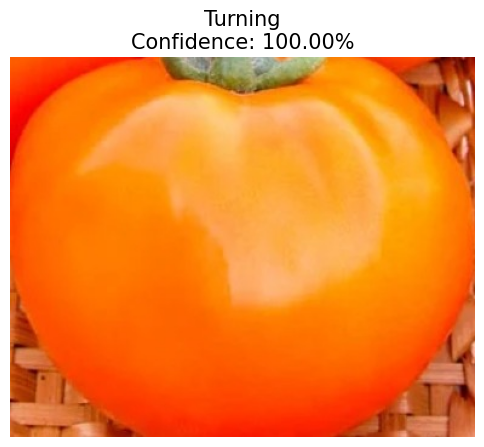

All predictions:
Mature Green: 0.00%
Breaker: 0.00%
Turning: 100.00%
Pink: 0.00%
Light Red / Red: 0.00%


In [12]:
uploaded = files.upload()

for filename, image_bytes in uploaded.items():

    image = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    resized = image.resize((224, 224))

    img_array = np.array(
        resized,
        dtype=np.float32
    )

    img_array = np.expand_dims(img_array, axis=0)

    predictions = model.predict(img_array, verbose=0)[0]

    index = np.argmax(predictions)
    confidence = predictions[index] * 100

    plt.figure(figsize=(6, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"{class_names[index]}\nConfidence: {confidence:.2f}%",
        fontsize=15
    )
    plt.show()

    print("All predictions:")
    for name, prob in zip(class_names, predictions):
        print(f"{name}: {prob * 100:.2f}%")